# Feature Scaling: Normalization

Normalization is a data preparation step where we change the values of numeric columns to a common scale, without distorting the differences in their ranges or losing information.

There are four common techniques:

1. MinMax scaling
2. Mean normalization
3. MaxAbs scaling
4. Robust scaling

Standardization used the mean and std. Normalization techniques mostly use the min, the max, or the median, so each one reacts differently to outliers.

## 1. MinMax Scaling

MinMax scaling squeezes every value into the range 0 to 1. The smallest value becomes 0 and the largest becomes 1.

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$



In [63]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import seaborn as sns

In [4]:
import pandas as pd
data = pd.read_csv(r'D:\coding\wine_data.csv', usecols=[0, 1, 2])
data.head(3)

,class_label,alcohol,malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36


<Axes: xlabel='alcohol', ylabel='malic_acid'>

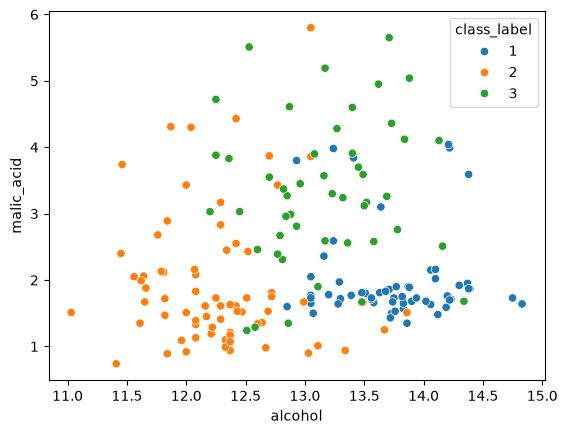

In [22]:
hex_palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

sns.scatterplot(data=data, x='alcohol', y='malic_acid', hue='class_label', palette=hex_palette)


In [36]:
x = data[['alcohol', 'malic_acid']]
y = data[['class_label']]

In [42]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size = 0.2,
    random_state = 42
)

In [43]:
print(x_train.size)
print(x_train.head(3))

284
     alcohol  malic_acid
158    14.34        1.68
137    12.53        5.51
98     12.37        1.07


In [44]:
print(x_test.size)
print(x_test.head(3))

72
     alcohol  malic_acid
19     13.64        3.10
45     14.21        4.04
140    12.93        2.81


In [50]:
mm_scaler = MinMaxScaler()
xtrain_scaled = mm_scaler.fit_transform(x_train).reshape(-1, 2)
xtest_scaled = mm_scaler.transform(x_test).reshape(-1, 2)

In [52]:
xtrain_scaled[:4]

array([[0.87105263, 0.16089613],
       [0.39473684, 0.94093686],
       [0.35263158, 0.03665988],
       [0.64473684, 0.15885947]])

In [53]:
xtest_scaled[:4]

array([[0.68684211, 0.45010183],
       [0.83684211, 0.64154786],
       [0.5       , 0.3910387 ],
       [0.71052632, 0.12423625]])

In [60]:
x_train.describe()

,alcohol,malic_acid
count,142.000000,142.000000
mean,12.979085,2.373521
std,0.820116,1.143934
min,11.030000,0.890000
25%,12.332500,1.615000
50%,13.010000,1.875000
75%,13.677500,3.135000
max,14.830000,5.800000


In [62]:
pd.DataFrame(xtrain_scaled).describe()

,0,1
count,142.000000,142.000000
mean,0.512917,0.302143
std,0.215820,0.232980
min,0.000000,0.000000
25%,0.342763,0.147658
50%,0.521053,0.200611
75%,0.696711,0.457230
max,1.000000,1.000000


Before scaling, the minimum and maximum values lie outside the 0 to 1 range after applying the MinMaxScaler, they are successfully bounded between 0 and 1.

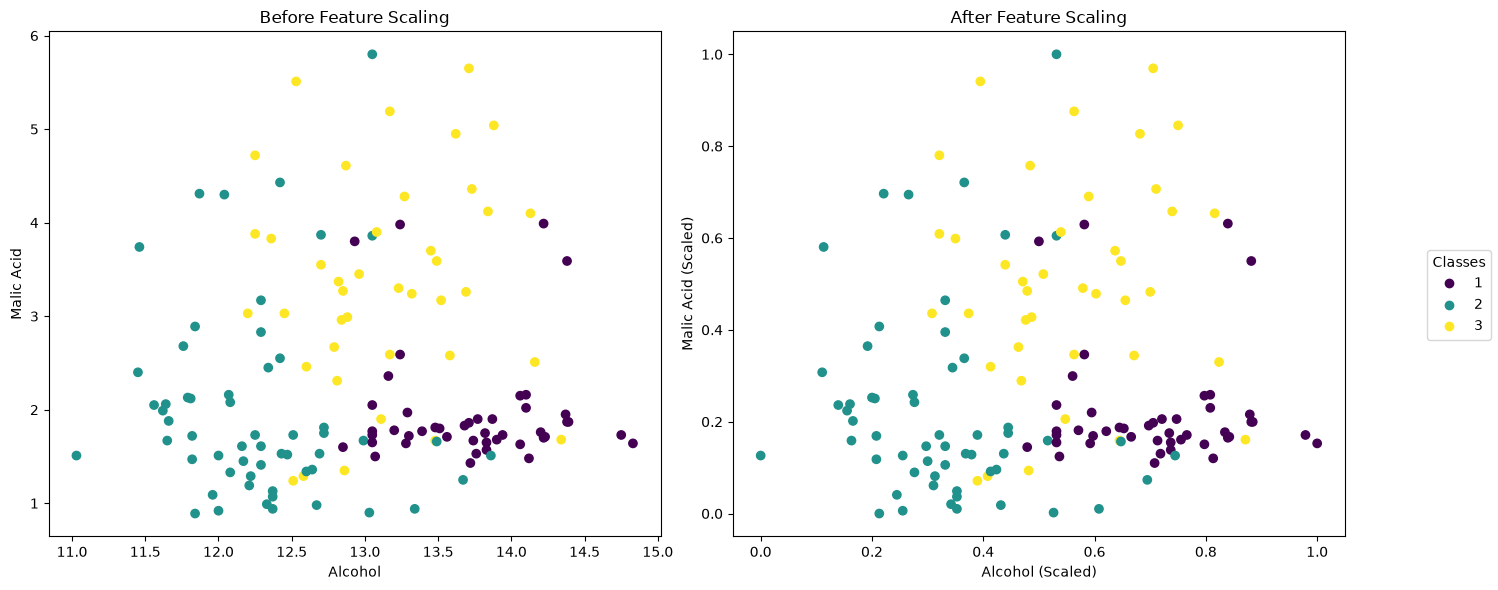

In [96]:
scaled_df = pd.DataFrame(xtrain_scaled, columns=x_train.columns)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# Plot 1: Before Scaling
scatter1 = ax[0].scatter(
    data=x_train, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    
)
ax[0].set_title('Before Feature Scaling')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')

# Plot 2: After Scaling
scatter2 = ax[1].scatter(
    data=scaled_df, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
)
ax[1].set_title('After Feature Scaling')
ax[1].set_xlabel('Alcohol (Scaled)')
ax[1].set_ylabel('Malic Acid (Scaled)')

handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")


plt.tight_layout()
plt.subplots_adjust(right=0.9) 
plt.show()


### After scaling, the data is squeezed into a square of area 1.

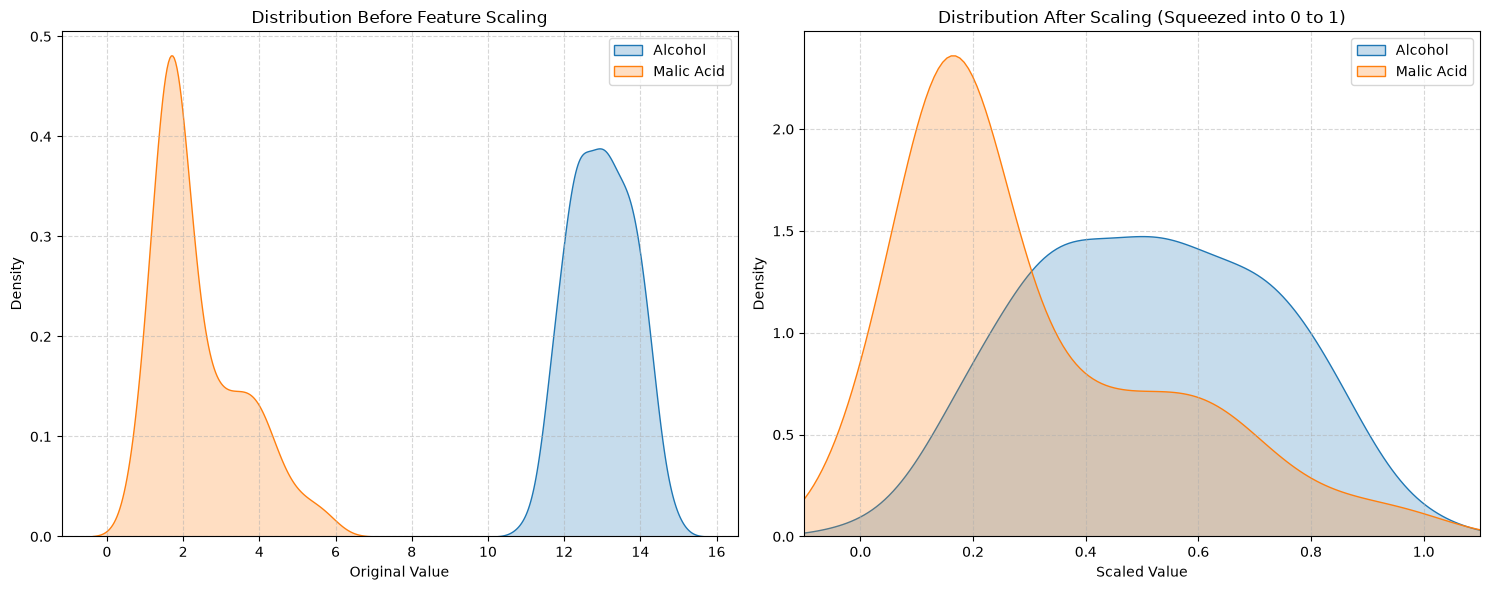

In [104]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# 1. Before Scaling (Original Scale)

sns.kdeplot(data=x_train, x='alcohol', label='Alcohol', fill=True, ax=ax[0])
sns.kdeplot(data=x_train, x='malic_acid', label='Malic Acid', fill=True, ax=ax[0])

ax[0].set_title('Distribution Before Feature Scaling')
ax[0].set_xlabel('Original Value')
ax[0].set_ylabel('Density')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)


# 2. After Scaling (Bounded Overlap)

sns.kdeplot(data=scaled_df, x='alcohol', label='Alcohol', fill=True, ax=ax[1])
sns.kdeplot(data=scaled_df, x='malic_acid', label='Malic Acid', fill=True, ax=ax[1])

# Constrain the view close to the scaled limits [0, 1] to avoid referencing
ax[1].set_xlim(-0.1, 1.1)

ax[1].set_title('Distribution After Scaling (Squeezed into 0 to 1)')
ax[1].set_xlabel('Scaled Value')
ax[1].set_ylabel('Density')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#  The Vulnerability of MinMax Scaling: The Outlier Compression Effect

## 1. Introduction
While **MinMax Normalization (Rescaling)** is highly effective for bounding data within a fixed, intuitive range like $[0, 1]$, it suffers from a significant limitation: **extreme sensitivity to outliers**. 

Because the scaling transformation is entirely dependent on the single absolute minimum ($X_{min}$) and maximum ($X_{max}$) values in the dataset, a solitary anomalous point can radically warp the relative distances of all other data points. Instead of preserving a meaningful distribution variance, the normal data structure gets heavily **compressed ("squashed")** into a tiny sub-region of the target area.

---

## 2. Mathematical Mechanics: Why Does It Squash?

To understand why this happens, look at the standard MinMax formula for a feature vector $X$:

$$X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

When an extreme upper outlier is introduced into the dataset, it dynamically shifts the value of $X_{max}$ to an artificially high number. Let's analyze the impact this has on the formula:

1. **Inflated Denominator:** The range term $(X_{max} - X_{min})$ becomes massive.
2. **Diminished Ratios:** For all standard, non-outlier data points, their actual values ($X$) are very small relative to the new, giant $X_{max}$. As a result, the numerator $(X - X_{min})$ stays comparatively tiny.
3. **Compression toward Zero:** Dividing a small numerator by a massive denominator forces the $X_{scaled}$ output for almost *all* regular data points to fall exceptionally close to `0`. 

### The Resulting Plot Distortion
* **The Outlier:** Sits isolated at exactly `(1.0, 1.0)`.
* **The Normal Data:** Entire valuable distribution of classes 1, 2, and 3 loses its visual resolution and gets violently squeezed into a small corner near `(0.0, 0.0)`. The model loses its ability to easily distinguish variance among normal samples because their relative numeric spread is heavily suppressed.


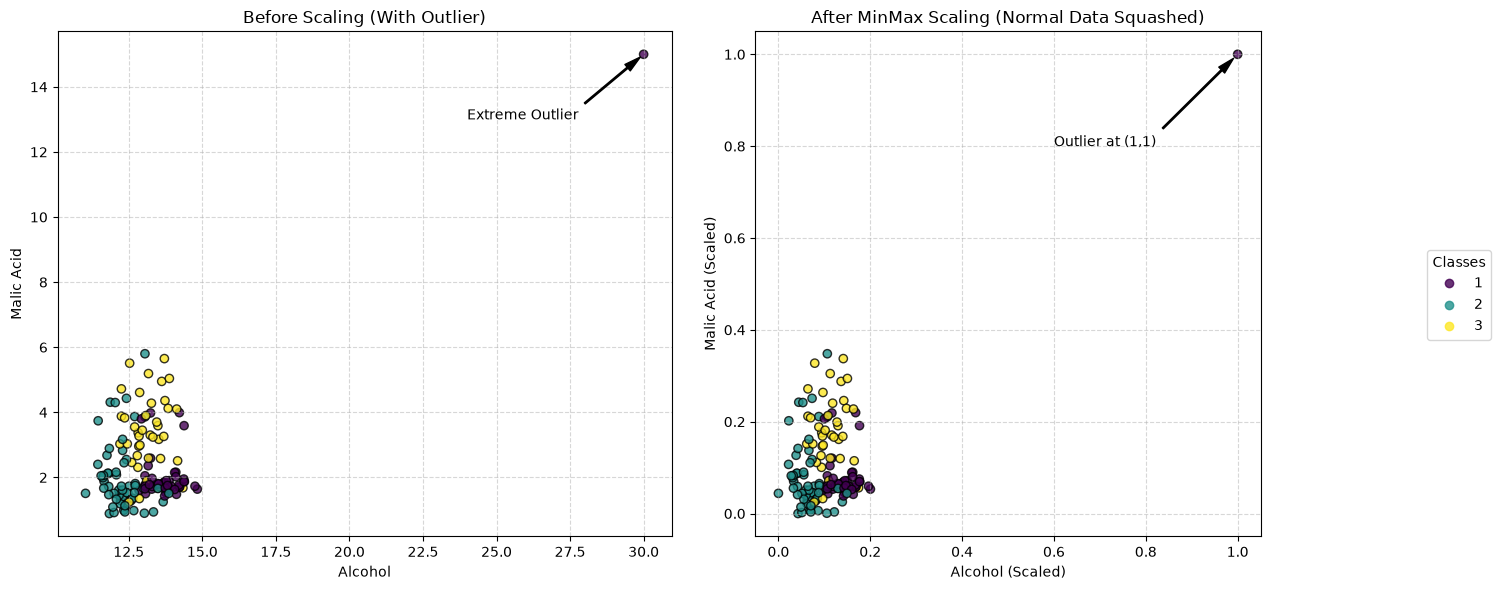

In [110]:
# Used AI for these graphs


outlier_x = pd.DataFrame([[30.0, 15.0]], columns=['alcohol', 'malic_acid'])
outlier_y = pd.DataFrame([[1]], columns=['class_label'])

x_train_with_outlier = pd.concat([x_train, outlier_x], ignore_index=True)
y_train_with_outlier = pd.concat([y_train, outlier_y], ignore_index=True)

# 2. Re-scale using MinMaxScaler with the outlier included
scaler = MinMaxScaler()
xtrain_scaled_outlier = scaler.fit_transform(x_train_with_outlier)
scaled_df_outlier = pd.DataFrame(xtrain_scaled_outlier, columns=x_train.columns)

# 3. Plot the visualization
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# --- Plot 1: Before Scaling with Outlier ---
scatter1 = ax[0].scatter(
    data=x_train_with_outlier, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
# Annotate the outlier so it's obvious
ax[0].annotate('Extreme Outlier', xy=(30.0, 15.0), xytext=(24, 13),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

ax[0].set_title('Before Scaling (With Outlier)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: After MinMax Scaling (Squashed Data) ---
scatter2 = ax[1].scatter(
    data=scaled_df_outlier, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
# Annotate where the outlier ended up (at exactly 1.0, 1.0)
ax[1].annotate('Outlier at (1,1)', xy=(1.0, 1.0), xytext=(0.6, 0.8),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

ax[1].set_title('After MinMax Scaling (Normal Data Squashed)')
ax[1].set_xlabel('Alcohol (Scaled)')
ax[1].set_ylabel('Malic Acid (Scaled)')
ax[1].grid(True, linestyle='--', alpha=0.5)

# Force the 1x1 square layout to see the empty space created
ax[1].set_aspect('equal', adjustable='box')
ax[1].set_xlim(-0.05, 1.05)
ax[1].set_ylim(-0.05, 1.05)

# Add Legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")
plt.tight_layout()
plt.subplots_adjust(right=0.88)

plt.show()


# 2. Mean Normalization: Shifting the Center to Zero
The MinMax Scaling earlier, it forced all my data to fit inside a strict box. Mean Normalization works differently. Instead of locking the minimum value at zero, it shifts the entire dataset so the distribution centers right on zero. 

Values smaller than the mean naturally become negative, and values larger than the mean become positive. Then, everything gets scaled down by the total range of the feature.

---

### Breaking Formula

Looking at the formula:

$$X'_i = \frac{X_i - X_{mean}}{X_{max} - X_{min}}$$

Here is how this actually changes the shape of the features step-by-step:

* **The Numerator ($X_i - X_{mean}$):** This handles the mean centering. If a data point is below average ($X_i < X_{mean}$), subtracting the mean gives a negative value ($-ve$). If it's above average ($X_i > X_{mean}$), it gives a positive value ($+ve$). If a sample lands exactly on the mean, it scales to a clean `0`.
* **The Denominator ($X_{max} - X_{min}$):** This divides everything by the total range. It keeps the scaled values bounded, usually spreading them out between roughly $[-1, 1].

### What This Means for the Plots
In the MinMax plots, the data got crammed into a square starting at the `(0,0)` origin. With Mean Normalization, the data will sit completely around the origin, meaning `(0,0)` will land right in the dead center of the data cluster.


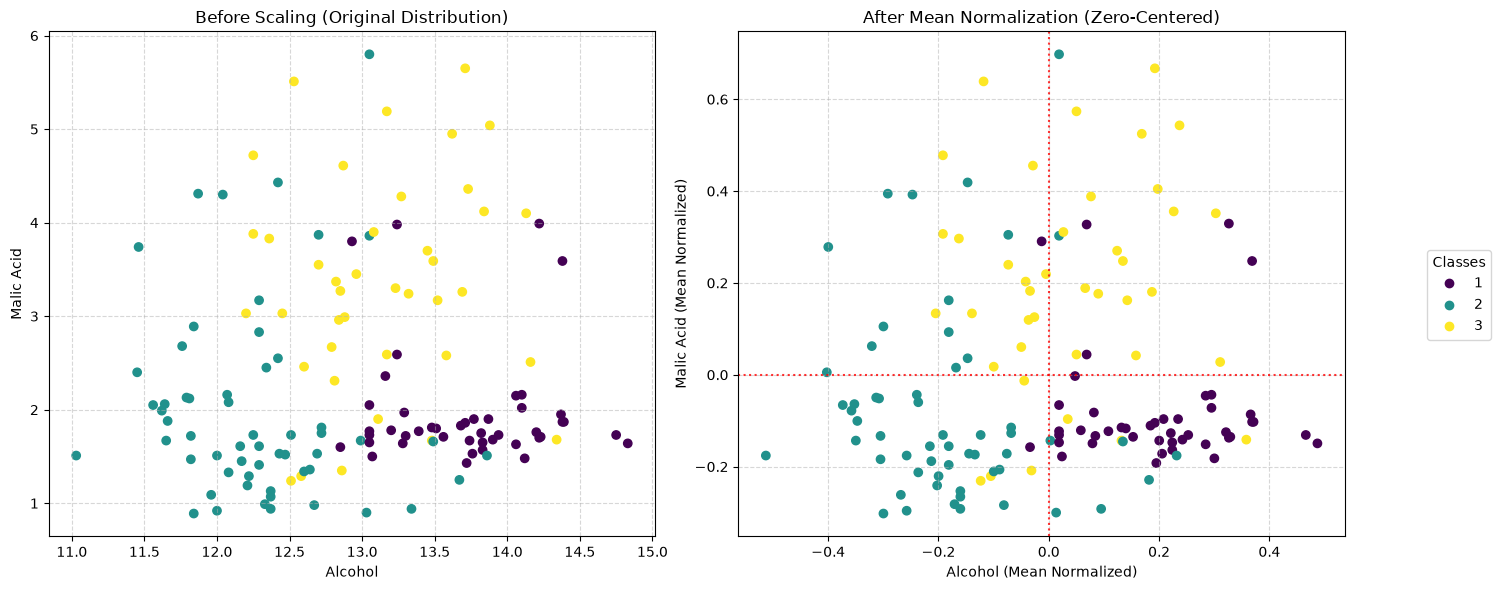

In [119]:
# Calculate Mean Normalization: (X - mean) / (max - min)
x_train_mean_norm = (x_train - x_train.mean()) / (x_train.max() - x_train.min())

# Initialize side-by-side subplots
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# ==========================================
# 1. Before Scaling
# ==========================================
scatter1 = ax[0].scatter(
    data=x_train, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label']
)
ax[0].set_title('Before Scaling (Original Distribution)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# ==========================================
# 2. After Mean Normalization (Centered at 0)
# ==========================================
scatter2 = ax[1].scatter(
    data=x_train_mean_norm, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label']
)
ax[1].set_title('After Mean Normalization (Zero-Centered)')
ax[1].set_xlabel('Alcohol (Mean Normalized)')
ax[1].set_ylabel('Malic Acid (Mean Normalized)')
ax[1].grid(True, linestyle='--', alpha=0.5)

# Add origin lines (crosshair) to clearly show the mean-centering effect at (0,0)
ax[1].axhline(0, color='red', linestyle=':', alpha=0.8, linewidth=1.5)
ax[1].axvline(0, color='red', linestyle=':', alpha=0.8, linewidth=1.5)

# Extract and apply a clean legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")

plt.tight_layout()
plt.subplots_adjust(right=0.9)
plt.show()


# 3. MaxAbsScaling: Scaling by the Peak Value

MaxAbsScaling is a simpler scaling trick. It just takes every value in a column and divides it by the absolute largest value in that same column. Unlike MinMax scaling, it does not shift or drag the data around. It just shrinks everything down by a single flat factor.

This is super helpful when the data already centers around zero or the data is sparse data like text matrices filled with tons of zeros. Since it only divides, any value that starts as a zero stays exactly a zero.

---

### Breaking Down the Formula

Looking at the formula:

$$X'_i = \frac{X_i}{|X_{max}|}$$

Here is how the transformation works in practice:

* **The Denominator ($|X_{max}|$):** This looks at the column and grabs the absolute largest value. Because it uses absolute bars, this number is always positive.
* **The Scaling Range:** When every single number is divided by the biggest absolute number in the group, that largest value automatically scales to exactly `1` or `-1` (if the largest value was negative e.g -4 /|-4| = -1 ). 
* **Keeping the Range Bounded:** This maps the entire dataset into a tight range between `-1` and `1`. If the original data only contains positive numbers, everything lands between `0` and `1`. It looks a lot like MinMax scaling, except we never subtracted the minimum value to shift it.

### What This Means for the Plots
Since MaxAbsScaling never subtracts anything to center the data or clear out the minimums, the original shape of the data remains completely unchanged. The whole plot just scales down proportionally so that the furthest edge hits a maximum boundary of 1.


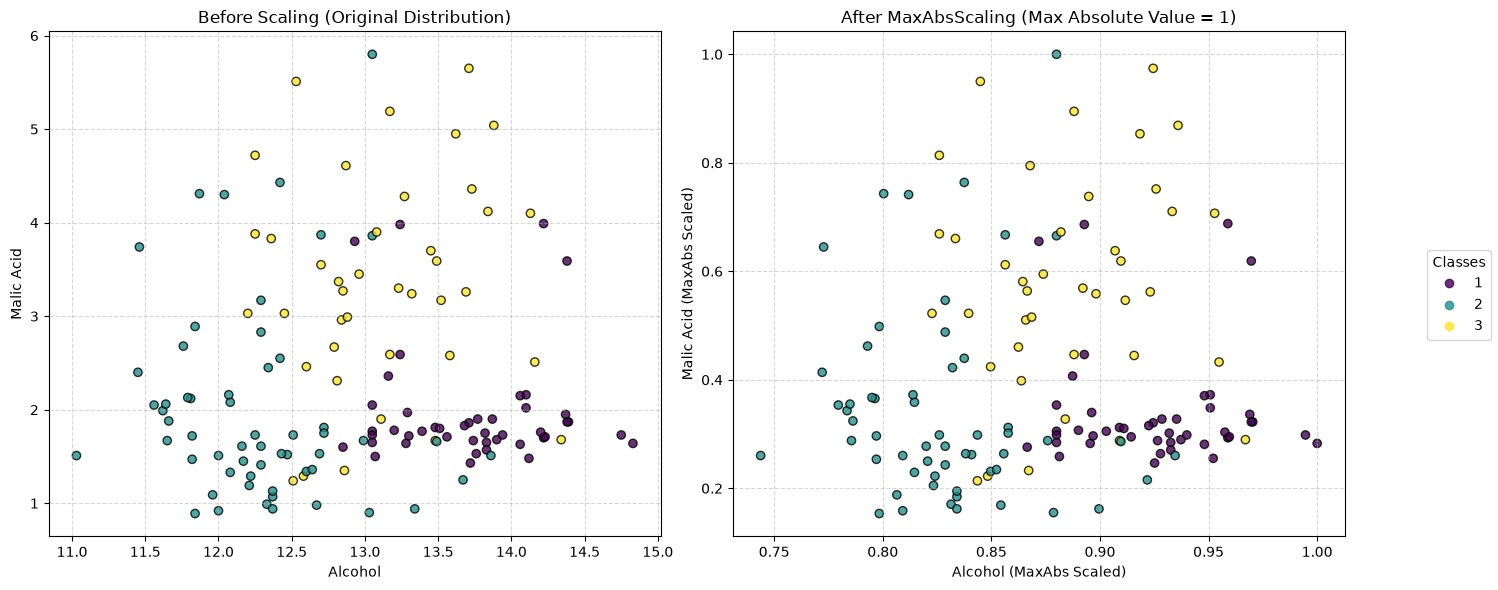

In [126]:
from sklearn.preprocessing import MaxAbsScaler

scaler = MaxAbsScaler()
xtrain_maxabs = scaler.fit_transform(x_train)
maxabs_df = pd.DataFrame(xtrain_maxabs, columns=x_train.columns)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# ==========================================
# 1. Before Scaling (Original Data)
# ==========================================
scatter1 = ax[0].scatter(
    data=x_train, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[0].set_title('Before Scaling (Original Distribution)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# ==========================================
# 2. After MaxAbsScaling (Bounded by Max 1.0)
# ==========================================
scatter2 = ax[1].scatter(
    data=maxabs_df, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[1].set_title('After MaxAbsScaling (Max Absolute Value = 1)')
ax[1].set_xlabel('Alcohol (MaxAbs Scaled)')
ax[1].set_ylabel('Malic Acid (MaxAbs Scaled)')
ax[1].grid(True, linestyle='--', alpha=0.5)



# Extract and apply a clean legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")

plt.tight_layout()
plt.subplots_adjust(right=0.9)
plt.show()


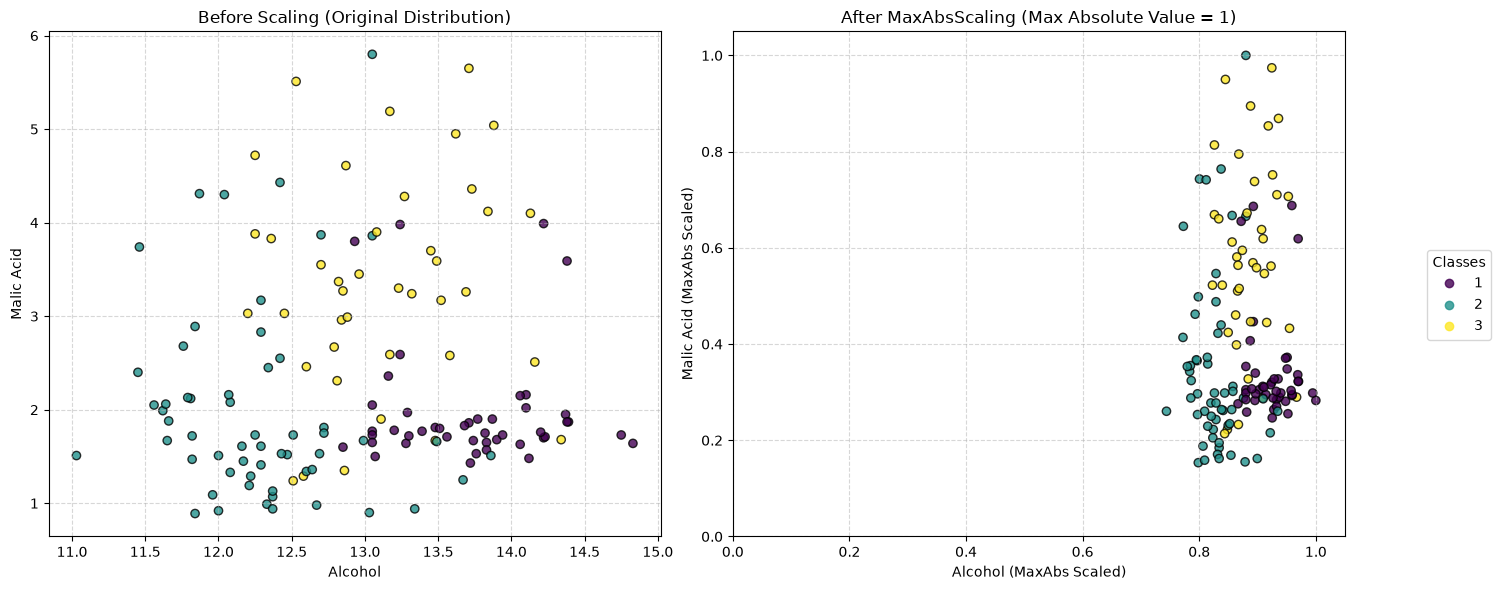

In [129]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# ==========================================
# 1. Before Scaling (Original Data)
# ==========================================
scatter1 = ax[0].scatter(
    data=x_train, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[0].set_title('Before Scaling (Original Distribution)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# ==========================================
# 2. After MaxAbsScaling (Bounded by Max 1.0)
# ==========================================
scatter2 = ax[1].scatter(
    data=maxabs_df, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[1].set_title('After MaxAbsScaling (Max Absolute Value = 1)')
ax[1].set_xlabel('Alcohol (MaxAbs Scaled)')
ax[1].set_ylabel('Malic Acid (MaxAbs Scaled)')
ax[1].grid(True, linestyle='--', alpha=0.5)

# Set limits to see the scaling boundary clearly
ax[1].set_xlim(0, 1.05)
ax[1].set_ylim(0, 1.05)

# Extract and apply a clean legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")

plt.tight_layout()
plt.subplots_adjust(right=0.9)
plt.show()


### Visualizing the Scale-in-Place Effect

When we enforce strict `[0, 1.05]` limits on our plot, we can see exactly how `MaxAbsScaler` behaves on our data. Unlike MinMax Scaling and Mean Normalization, it does not shift, center, or stretch our distribution,, it simply scales it in place.

Looking closely at the right-hand plot, notice how the Alcohol values are clumped together between `0.7` and `1.0`. This leaves a large empty gap sitting between `0.0` and `0.7`.

This happens because `MaxAbsScaler` only divides by the absolute maximum value:
* The highest Alcohol value (~15.0) scales to exactly `1.0`.
* The lowest Alcohol value (~11.0) directly becomes `11.0 / 15.0 ≈ 0.73`.

Because this technique never subtracts a minimum value or a mean value, it does not shift the distribution over to or around the origin. The original relative spacing, shape, and distances between our data points are perfectly preserved. The entire structure is simply shrunken down proportionally until the largest absolute value hits the boundary of 1.


# 4. Robust Scaling: Handling Heavy Outliers

When a dataset contains extreme outliers, methods like MinMax Scaling or Standardization get heavily distorted because their formulas rely on the absolute maximums, minimums, or means. Robust Scaling solves this by focusing entirely on statistics that ignore extreme values: the **Median** and the **Interquartile Range (IQR)**.

---

### Breaking Down the Formula


$$X'_i = \frac{X_i - X_{median}}{IQR}$$

Here is how this transformation works step-by-step:

* **The Numerator ($X_i - X_{median}$):** Instead of using the mean, we subtract the median (the middle value of the data). Since the median isn't dragged away by massive outliers the way a mean is, this centers the bulk of the data reliably around `0`.
* **The Denominator ($IQR$):** The Interquartile Range is calculated as the 75th percentile minus the 25th percentile ($Q3 - Q1$).Dividing by the range of the middle 50% of the data, the scaling factor completely ignores the top 25% and bottom 25% where the anomalies live.

### What This Means for the Plots
Because the outliers are completely left out of the scaling calculations, the normal data points don't get squished or compressed into a tiny corner. The main cluster of your data will stretch out beautifully across a comfortable range around `0`, while the extreme outliers are allowed to sit far off the plot area on their own without breaking your feature distribution.


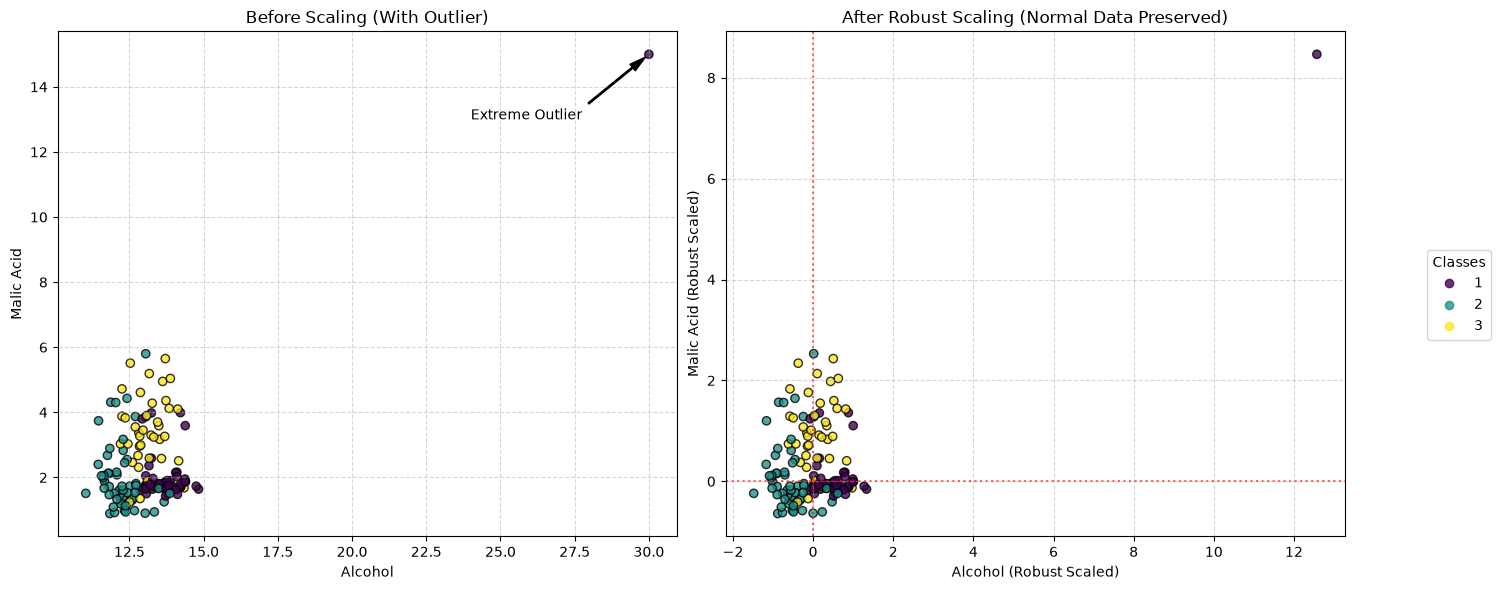

In [141]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
xtrain_robust = scaler.fit_transform(x_train_with_outlier)
robust_df = pd.DataFrame(xtrain_robust, columns=x_train.columns)

# Initialize side-by-side subplots
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# ==========================================
# 1. Before Scaling (With Extreme Outlier)
# ==========================================
scatter1 = ax[0].scatter(
    data=x_train_with_outlier, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[0].set_title('Before Scaling (With Outlier)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# Annotate the extreme outlier point
ax[0].annotate('Extreme Outlier', xy=(30.0, 15.0), xytext=(24, 13),
               arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# ==========================================
# 2. After Robust Scaling (Outlier Defeated)
# ==========================================
scatter2 = ax[1].scatter(
    data=robust_df, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
ax[1].set_title('After Robust Scaling (Normal Data Preserved)')
ax[1].set_xlabel('Alcohol (Robust Scaled)')
ax[1].set_ylabel('Malic Acid (Robust Scaled)')
ax[1].grid(True, linestyle='--', alpha=0.5)


# Add origin lines to show center at median (0,0)
ax[1].axhline(0, color='red', linestyle=':', alpha=0.6, linewidth=1.5)
ax[1].axvline(0, color='red', linestyle=':', alpha=0.6, linewidth=1.5)

# Extract and apply clean legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")

plt.tight_layout()
plt.subplots_adjust(right=0.9)
plt.show()


In [140]:
print(x_train_with_outlier.median())
print(x_train_with_outlier.max())
print(x_train_with_outlier.quantile(.25))
print(x_train_with_outlier.quantile(.75))
(x_train_with_outlier.max() - x_train_with_outlier.median()) / (x_train_with_outlier.quantile(.75) - x_train_with_outlier.quantile(.25))

alcohol       13.03
malic_acid     1.88
dtype: float64
alcohol       30.0
malic_acid    15.0
dtype: float64
alcohol       12.335
malic_acid     1.620
Name: 0.25, dtype: float64
alcohol       13.685
malic_acid     3.170
Name: 0.75, dtype: float64


alcohol       12.570370
malic_acid     8.464516
dtype: float64

### Proving the Math Behind the Robust Transformation

By running the calculations manually, we can see the exact coordinates where our extreme outlier gets placed on the new robust scale:

$$X'_{scaled} = \frac{X_{max} - X_{median}}{Q_3 - Q_1}$$

Plugging in our actual data values:
* **Alcohol Outlier Coordinate:** $\frac{30.0 - 13.03}{13.685 - 12.335} = \mathbf{12.57}$
* **Malic Acid Outlier Coordinate:** $\frac{15.0 - 1.88}{3.17 - 1.62} = \mathbf{8.46}$

This perfectly demonstrates the core philosophy of `RobustScaler`. Because it scales the data using the stable middle 50% (the IQR), the normal data points are distributed naturally within a tight window. Meanwhile, the outlier doesn't distort the scaling factor; it simply handles its own massive variance by landing far off-screen at $(12.57, 8.46)$. This is why our core distribution remains readable and entirely unsquashed.


### Comparing MinMax Scaling vs. Robust Scaling with Outliers

Looking at these two sets of plots side-by-side reveals exactly why choosing the right scaler matters when your data has extreme anomalies. 

#### The MinMax Problem: Distribution Squashing
In the first visualization using **MinMax Scaling**, the extreme outlier forces the entire normal distribution to collapse. 
* Because the formula bounds everything strictly between `0` and `1` using the absolute maximum value, the outlier claims the `(1.0, 1.0)` spot.
* This drags the rest of data into a tight, compressed cluster down between `0.0` and `0.2` on the X-axis. 
* The internal variance and shape of classes are heavily suppressed because one single point dictated the scale for the entire feature space.

#### The Robust Solution: Preserving the Core Shape
In the second visualization using **Robust Scaling**, dataset is saved from this compression effect.
* Because the formula relies on the median and the Interquartile Range (IQR), it scales the data based on where the middle 50% of samples live.
* The main data cluster spreads out naturally, centering beautifully around the `(0,0)` origin lines. Its original distribution shape and relative distances are perfectly preserved.
* The extreme outlier doesn't ruin the scaling factor for the other points; it simply takes on its true scaled coordinates and sits harmlessly at `(12.57, 8.46)`, completely isolated from the rest of the group.

---

### Feature Scaling Comparison Summary

| Scaler | Centered At | Sensitive to Outliers? | Best Use Case |
| :--- | :--- | :--- | :--- |
| **MinMax Scaler** | Minimum shifted to `0` | **Yes** (Squashes normal data) | When we need strict `[0, 1]` bounds and have no outliers. |
| **Mean Normalizer** | Mean centered at `0` | **Yes** (Mean gets dragged by anomalies) | Simple algorithms requiring zero-centered data without heavy outliers. |
| **MaxAbs Scaler** | Not centered (Scales in place) | **Yes** (Max value scales to `1` or `-1`) | Sparse data (like text matrices) where preserving zeros is critical. |
| **Robust Scaler** | Median centered at `0` | **No** (Uses stable Median and IQR) | Datasets with heavy anomalies or extreme outliers. |
